# Perturb demo C: designing an instrument with a least-squares retrieval

Gaussian perturbation explains a black-box's answer for a single sample. It nudges a small, smooth region of the input
up and down by a few times its noise, and records how the answer moves. Doing this at every position gives a map of
which parts of the input each output depends on, and in which direction.

The method needs nothing from the black-box except inputs in and answers out, so here the black-box is a plain
**least-squares fit** rather than a neural network. We use its explanation to find which parts of an observation
carry the result, and then reshape the instrument around them.

**The problem.** A spectrum on a fine native grid $\lambda \in [0, 10]$ is set by 5 unknown amplitudes
$a_k \sim U(0.1, 2)$, each of which scales a fixed band shape $b_k(\lambda)$, and saturates where it is deep:

$$d(\lambda) = 1 - \exp\Big(-\sum_k a_k\, b_k(\lambda)\Big), \qquad b_k(\lambda) = \sum_j h_{kj}\, e^{-(\lambda-\mu_{kj})^2 / 2 s_{kj}^2}.$$

Every Gaussian has its own fixed width, so the bands overlap their neighbours by different amounts, and every
amplitude controls two or three Gaussians in different places. This means that neighbouring amplitudes are partly
degenerate, as more of one can be traded for less of another.

**The available instrumentation** sits side by side along $\lambda$, with 4 overlapping photometric **filters** (one
point each, each with its own noise), which can each be kept or dropped. These are followed by two **spectrographs**,
S1 and S2, which can be **cropped** from either end, and whose interior bins can be **merged** with a neighbour,
trading resolution for less noise. The noise is only drawn once, so every configuration sees the same noise
realisation.

**The black-box** is `scipy.optimize.least_squares`, fitting the forward model (averaged over each point's bandpass)
to one observation. It only fits one observation per call, which is the case `Perturber(batch_size=1)` is for.

**The method** has four steps, followed by the design loop:
1. `perturb.fit_kernel_width` finds the kernel width, i.e. how far apart two points can be and still move together.
2. `perturb.in_distribution_curve` finds how large a perturbation the retrieval can still handle the same way it
   handles a small one.
3. `perturb.Perturber` calculates the response of $f$ to every perturbation of the observation, and the importance.
4. `perturb.plotting` draws the figures.
5. The design loop scores every point by its importance to the parameters we care about, removes the least important,
   refits, and repeats.

In [1]:
import sys
from pathlib import Path
from IPython.display import display


import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "instrument")                       # the demo problem; `pip install -e ..` installs perturb itself
sys.path.insert(0, str(Path("..", "src").resolve()))  # ... or use it straight from the repo
import perturb as pt
from perturb import plotting
import instrument as ins
from tqdm import tqdm

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
rng = np.random.default_rng(1)

## The available instrumentation

This is everything the instrument could carry, before we look at anything. The top panel shows the transmission of
each element. The 4 filters are skewed, unevenly spaced and overlap their neighbours, so some of
them may turn out to be redundant. A filter's point is the spectrum averaged with its profile as the weight, placed at
the profile's effective wavelength (the square below). The two spectrographs have flat bins, with a tick at every bin
edge on a line over the spectrograph's range; S1 has 54 narrow bins, and S2 has 26 wider ones. The bottom panel shows
the noise of every data point, which ramps up logarithmically along each spectrograph. A merged bin averages its
pixels, so its noise is lower than that of either bin on its own.

84 points: 4 filters, 54 S1 bins, 26 S2 bins


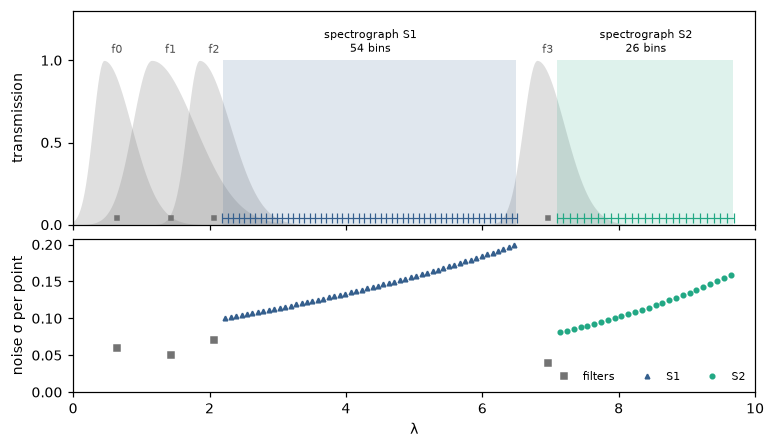

In [2]:
FILTER_C = "0.45"
SPEC_C = dict(zip(ins.SPECTROGRAPHS, plt.cm.viridis([0.3, 0.6])))
SPEC_M = dict(zip(ins.SPECTROGRAPHS, ["^", "o"]))   # S1 triangles, S2 dots, everywhere

def draw_bins(ax, name, e, y, h):
    # draw a spectrograph's bins at height y, as a line over its extent with a tick of half-height h at every bin
    # edge (merged bins have their edges further apart)
    dl = ins.LAM[1] - ins.LAM[0]
    x = ins.LAM[0] + (np.asarray(e) - 0.5) * dl            # edge between native pixels e - 1 and e
    ax.hlines(y, x[0], x[-1], color=SPEC_C[name], lw=0.8)
    ax.vlines(x, y - h, y + h, color=SPEC_C[name], lw=0.8)

def draw_filters(ax, filters, base=0, height=1, transform=None, **kw):
    # fill each selected filter's transmission profile from base up to base + height * profile
    for i in filters:
        prof = ins.FILTER_PROFILES[i]
        ax.fill_between(ins.LAM, base, base + height * prof, where=prof > 0, transform=transform or ax.transData,
                        color="0.5", alpha=0.25, lw=0, **kw)

def draw_instrument(ax, config, obs=None, spectrum=True, y=(0, 0.04)):
    # draw the true spectrum, the selected filters and spectrograph bins, and optionally an observation
    if spectrum:
        ax.plot(ins.LAM, ins.total_depth(A_TRUE), color="k", lw=1, label="true spectrum")
    draw_filters(ax, config["filters"], height=0.5, transform=ax.get_xaxis_transform())
    for name in ins.SPECTROGRAPHS:
        if config[name] is not None:
            e = config[name]
            draw_bins(ax, name, e, y[0], 0.02)
    if obs is not None:
        f = np.char.startswith(obs["element"], "f")
        ax.errorbar(obs["x_axis"][f], obs["y"][f], obs["sigma"][f], fmt="s", ms=4, color=FILTER_C, elinewidth=0.8,
                    label="filters")
        for name in ins.SPECTROGRAPHS:
            g = obs["element"] == name
            ax.errorbar(obs["x_axis"][g], obs["y"][g], obs["sigma"][g], fmt=SPEC_M[name], ms=3, color=SPEC_C[name],
                        elinewidth=0.6, label=name)
        ax.axhline(ins.CLOUD_DECK, color="0.5", lw=0.8, ls="--", label="cloud deck")

    ax.set_xlim(0, 10)

full = ins.full_config()
layout = ins.instrument(full)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, gridspec_kw=dict(height_ratios=[1.4, 1], hspace=0.08))
draw_filters(a1, full["filters"])
for i, c in enumerate(ins.FILTER_CENTRES):
    a1.text(c, 1.03, f"f{i}", ha="center", va="bottom", fontsize=7, color="0.3")
    a1.plot(c, 0.04, "s", color=FILTER_C, ms=3)
for name in ins.SPECTROGRAPHS:
    e = full[name]
    a1.fill_between([ins.LAM[e[0]], ins.LAM[e[-1] - 1]], 0, 1, color=SPEC_C[name], alpha=0.15, lw=0)
    draw_bins(a1, name, e, 0.04, 0.03)
    a1.text(ins.LAM[e[[0, -1]]].mean(), 1.03, f"spectrograph {name}\n{len(e) - 1} bins", ha="center", va="bottom", fontsize=7)
a1.set_ylim(0, 1.3); a1.set_yticks([0, 0.5, 1]); a1.set_ylabel("transmission")
f = np.char.startswith(layout["element"], "f")
a2.plot(layout["x_axis"][f], layout["sigma"][f], "s", color=FILTER_C, ms=4, label="filters")
for name in ins.SPECTROGRAPHS:
    g = layout["element"] == name
    a2.plot(layout["x_axis"][g], layout["sigma"][g], SPEC_M[name], color=SPEC_C[name], ms=3, label=name)
a2.set_ylim(0, None); a2.set_xlim(0, 10); a2.set_xlabel("λ"); a2.set_ylabel("noise σ per point")
a2.legend(fontsize=7, frameon=False, ncols=3, loc="lower right")
fig.align_ylabels([a1, a2])
print(f"{len(layout['x_axis'])} points: {len(full['filters'])} filters, "
      + ", ".join(f"{(layout['element'] == n).sum()} {n} bins" for n in ins.SPECTROGRAPHS))

## The parameters, and the sample

We fix the true amplitudes first. The instrument is designed for all of them, since with degenerate bands, losing the
data that pins down one amplitude lets it trade off against its neighbours, and their precision goes too. Every
amplitude has bands in more than one place. For example, $a_5$ has one under the filters and a broad one in S2, so it
can be read from either, and $a_4$ has one at the red end of S1, next to filter f3, and another in S2.

The top panel shows the true spectrum, and the observation $x^\star$ that the full instrument makes of
it, which is the sample we want to explain. The bottom panel shows the same spectrum taken apart into the optical
depth each amplitude contributes on its own, $a_k b_k(\lambda)$, each drawn at its own height. Most points carry more
than one amplitude, and every amplitude shows up more than once.

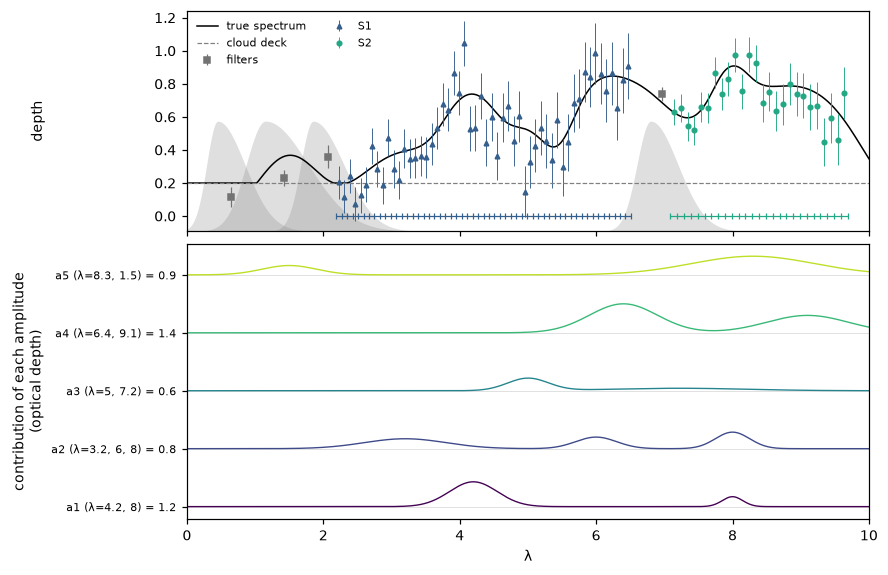

In [3]:
A_TRUE = np.array([1.2, 0.8, 0.6, 1.4, 0.9])
EXAMPLES = [3, 4]                                   # a4, a5: the amplitudes whose maps we draw below
obs = ins.observe(full, A_TRUE)

fig, (ax, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw=dict(height_ratios=[1.2, 1.5], hspace=0.05))
draw_instrument(ax, full, obs)
ax.set_ylabel("depth"); ax.legend(fontsize=7, frameon=False, loc="upper left", ncols=2)
# the same spectrum taken apart into each amplitude's optical depth a_k b_k, drawn at its own height
spacing = 2 * ins.contribution(A_TRUE).max()
for k, (band, colour) in enumerate(zip(ins.contribution(A_TRUE), plt.cm.viridis(np.linspace(0, 0.9, len(ins.NAMES))))):
    a2.axhline(k, color="0.85", lw=0.5)
    a2.plot(ins.LAM, k + band / spacing, color=colour, lw=0.9)
a2.set_yticks(range(len(ins.NAMES)), [f"{n} = {a:g}" for n, a in zip(ins.NAMES, A_TRUE)], fontsize=7)
a2.set_xlabel("λ"); a2.set_ylabel("contribution of each amplitude\n(optical depth)")
fig.align_ylabels([ax, a2]);

## The black-box

`ins.retrieval(obs)` returns `f`, which takes observations $(N, M)$ and returns amplitudes $(N, P)$, running one
least-squares fit per row. This is all Perturb needs from a black-box. The observation itself is fitted from 8 random
starting points, and the best fit is kept. Every other row (i.e. every perturbed sample) is warm-started from that
solution, so that the perturbations are followed along the same branch rather than jumping between local minima.

The retrieved covariance comes from the fit's Jacobian and the prior, $(J^\top \Sigma^{-1} J + \Sigma_\text{prior}^{-1})^{-1}$.
On the left is the true spectrum (black), and the retrieved amplitudes put back through the forward model,
$g(f(x^\star))$ (red), with the 1σ spread of spectra drawn from that covariance shaded. On the right is a **corner
plot** of the posterior, taken as the Gaussian with that covariance. The diagonal shows the marginal of each
amplitude, and every other panel shows the joint posterior of a pair, as its 1σ ellipse (solid) and its 2σ ellipse
(dashed and lighter). The 1σ ellipse is the contour whose shadow on each axis is the ±1σ marginal, and the diagonal
shades ±1σ and ±2σ in the same way. The truth is marked by the black lines. Tilted ellipses show the degeneracies,
where more of one amplitude can be traded for less of another. Their widths are the figure of merit for the
design loop.

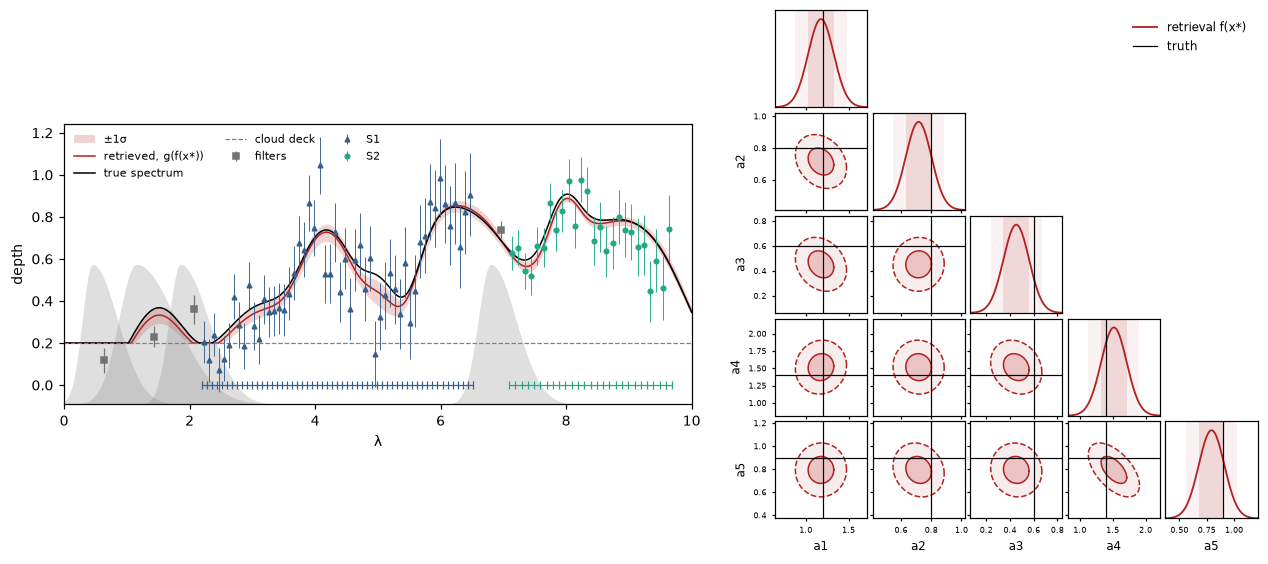

In [4]:
f = ins.retrieval(obs)
cov = ins.covariance(obs, f.best)
sig = np.sqrt(np.diag(cov))

def corner(fig, cell, entries, truth=A_TRUE):
    # a lower-triangle corner plot of Gaussian posteriors, where entries = [(label, mean, cov, colour), ...]
    P = len(truth)
    gs = cell.subgridspec(P, P, hspace=0.06, wspace=0.06)
    sd = [np.sqrt(np.diag(c)) for _, _, c, _ in entries]
    lo = np.min([m - 3 * s for (_, m, _, _), s in zip(entries, sd)] + [truth], axis=0)
    hi = np.max([m + 3 * s for (_, m, _, _), s in zip(entries, sd)] + [truth], axis=0)
    lo, hi = lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo)
    t = np.linspace(0, 2 * np.pi, 100)
    for i in range(P):
        for j in range(i + 1):
            ax = fig.add_subplot(gs[i, j])
            for (label, m, c, colour), s in zip(entries, sd):
                if i == j:
                    x = np.linspace(lo[i], hi[i], 200)
                    ax.plot(x, np.exp(-0.5 * ((x - m[i]) / s[i]) ** 2), color=colour, lw=1.2, label=label)
                    for n, alpha in ((2, 0.06), (1, 0.12)):  # 2 sigma, then 1 sigma on top
                        ax.axvspan(m[i] - n * s[i], m[i] + n * s[i], color=colour, alpha=alpha, lw=0)
                else:
                    L = np.linalg.cholesky(c[np.ix_([j, i], [j, i])])
                    for n, alpha, ls in ((2, 0.08, "--"), (1, 0.2, "-")):  # 2 sigma, then 1 sigma on top
                        xy = m[[j, i], None] + n * L @ np.array([np.cos(t), np.sin(t)])
                        ax.fill(*xy, color=colour, alpha=alpha, lw=0)
                        ax.plot(*xy, color=colour, lw=1, ls=ls)
            ax.axvline(truth[j], color="k", lw=0.8)
            if i != j:
                ax.axhline(truth[i], color="k", lw=0.8)
                ax.set_ylim(lo[i], hi[i])
            else:
                ax.set_ylim(0, 1.1); ax.set_yticks([])
            ax.set_xlim(lo[j], hi[j])
            ax.tick_params(labelsize=5, length=2)
            if i < P - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(ins.NAMES[j].split(" ")[0], fontsize=8)
            if j > 0 and i != j:
                ax.set_yticklabels([])
            elif i != j:
                ax.set_ylabel(ins.NAMES[i].split(" ")[0], fontsize=8)
            if i == j == 0:
                handles = ax.get_legend_handles_labels()
    handles[0].append(plt.Line2D([], [], color="k", lw=0.8)); handles[1].append("truth")
    fig.add_subplot(gs[0, P // 2 + 1:]).axis("off")
    fig.axes[-1].legend(*handles, fontsize=8, frameon=False, loc="upper right")

def retrieved_spectrum(ax, o, a):
    # draw g(f(x*)) on the native grid, with the 16-84 percentile range of spectra drawn from the retrieved covariance
    draws = np.clip(np.random.default_rng(0).multivariate_normal(a, ins.covariance(o, a), 2000), ins.A_LO, ins.A_HI)
    lo, hi = np.percentile(ins.total_depth(draws), [16, 84], axis=0)
    ax.fill_between(ins.LAM, lo, hi, color="firebrick", alpha=0.2, lw=0, label="±1σ")
    ax.plot(ins.LAM, ins.total_depth(a), color="firebrick", lw=1, label="retrieved, g(f(x*))")

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=0.15)
a1 = fig.add_subplot(gs[0].subgridspec(3, 1, height_ratios=[0.6, 2, 0.6])[1])
retrieved_spectrum(a1, obs, f.best)
draw_instrument(a1, full, obs)
a1.set_xlabel("λ"); a1.set_ylabel("depth"); a1.legend(fontsize=7, frameon=False, ncols=3, loc="upper left")
corner(fig, gs[1], [("retrieval f(x*)", f.best, cov, "firebrick")]);

## Step 1: the width of the Gaussian kernel

Real spectra never jump at a single point, so rather than perturbing points one at a time, Gaussian perturbation moves
a neighbourhood of points together, using a window as wide as the scale over which real observations are correlated.
`fit_kernel_width` measures this scale from noiseless observations of prior samples, made with the full instrument. It
calculates the Pearson correlation of every pair of points, bins these by their separation in $\lambda$, and fits a
Gaussian to the result. The full instrument samples the spectrum densely enough to fit this directly, and points under
overlapping filters simply come out highly correlated, as they should.

The broad bands overlap so much that whole spectra rise and fall together with the overall amount of absorption, and
this common offset would make every pair of points look correlated. To avoid this, each spectrum is min-max normalised
first (`normalise=True`), so that the fit measures how far the *shape* is shared.

The FWHM is in units of wavelength, and every configuration in the design loop reuses it.

kernel FWHM = 1.521 ± 0.016 in λ


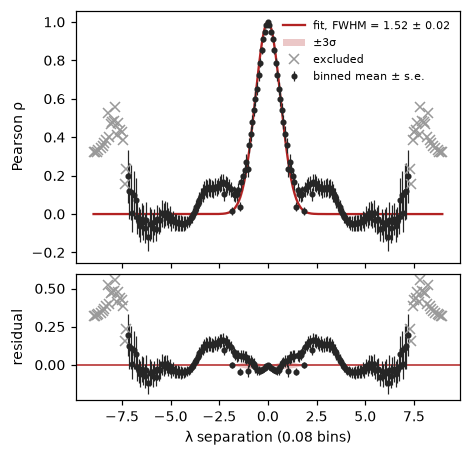

In [5]:
X_prior = ins.forward(obs)(ins.sample_amplitudes(5000, rng))     # noiseless observations of prior samples

fit = pt.fit_kernel_width(X_prior, obs["x_axis"], normalise=True)
FWHM = fit["fwhm"]
print(f"kernel FWHM = {FWHM:.3f} ± {fit['fwhm_err']:.3f} in λ")
plotting.kernel_fit(fit, xlabel="λ separation");

The correlation falls off over about the width of one band, as a point moves with its neighbours because they sit
under the same bands. The correlation matrix shows this as a band along the diagonal, where the 4 filters are the
coarse cells at the bottom left and the two spectrographs are the fine ones.

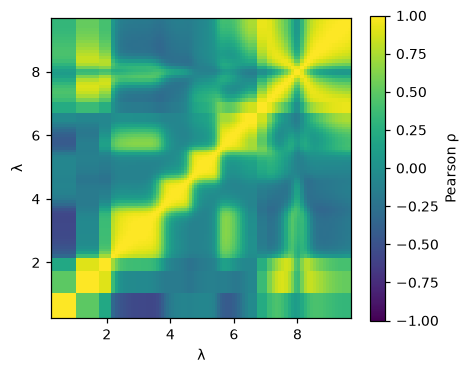

In [6]:
plotting.correlation_matrix(fit, xlabel="λ");

## Step 2: how far to perturb

For a centre point $m$ and magnitudes $\boldsymbol\xi$, the perturbed samples are
$X'_m = \mathbf{1}_K x^\star + \boldsymbol\xi\, \boldsymbol\sigma \odot \mathbf{w}(\varepsilon, m)$, where $\mathbf w$
is the Gaussian window of FWHM $\varepsilon$. Here every point moves by its **own** noise (`scale="own"`), as the noise
jumps between the filters and the spectrograph bins. The default, `scale="centre"`, instead moves every point by the
noise of the centre point, which keeps the window smooth. `batch_size=1` hands `f` one perturbed observation per call,
for retrievals that can't take a batch.

First we perturb every centre over a deliberately wide range of magnitudes, $\pm$`XI_EXPLORE`. If the limit found
below is at the edge of this range, widen it.

In [7]:
XI_EXPLORE = 5    # in sigma; widen this if the limit below comes out at the edge
perturber = pt.Perturber(f, obs["x_axis"], obs["sigma"], FWHM, scale="own", batch_size=1)
wide = perturber(obs["y"], pt.magnitude_grid(xi_max=XI_EXPLORE, n=41))

We then ask the retrieval itself. Each of its answers is put back through the forward model, and we measure how much
of the perturbation that best fit reproduces, which we call the **fraction fitted**,

$$F = \frac{\Delta\text{fit} \cdot \Delta x}{\Delta x \cdot \Delta x}, \qquad \Delta x = X' - x^\star, \quad \Delta\text{fit} = g(f(X')) - g(f(x^\star)),$$

where both are in units of the noise. $F = 1$ means the fit explains the whole perturbation as signal, and $F = 0$
means it treats it as noise. While $F$ stays within `tol` of its value at the smallest $\xi$, the retrieval is
treating a bigger perturbation the same way it treats a small one, and we count the perturbed sample as **in
distribution** (inside the black line).

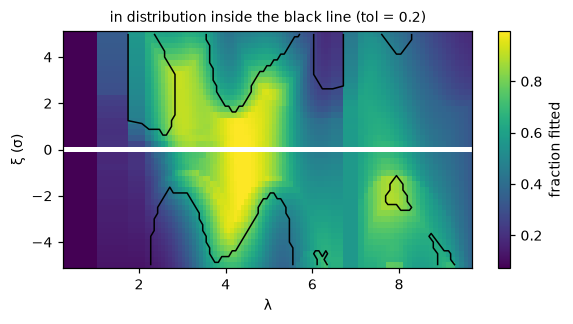

In [8]:
curve = pt.in_distribution_curve(wide, ins.forward(obs), tol=0.2)
plotting.ood_map(curve, wide, xlabel="λ");

The curve summarises the map, giving the fraction of columns still inside the black line at each magnitude.
`max_magnitude` then reads off the largest $|\xi|$ at which at least 95 per cent of them are.

in distribution up to |xi| = 0.75 sigma


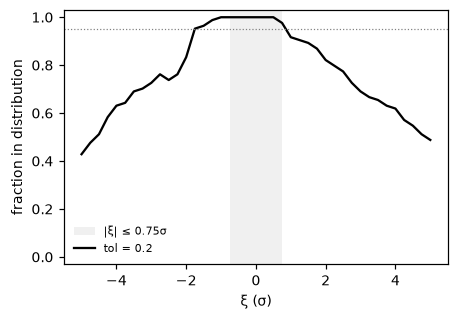

In [9]:
XI_MAX = pt.max_magnitude(curve)
print(f"in distribution up to |xi| = {XI_MAX:g} sigma")
plotting.in_distribution(curve);

## Step 3: perturb the observation

Each perturbed sample costs one least-squares fit, and the fit at $\xi = 0$ is shared by every centre, so a run is
$M \times (K - 1) + 1$ fits. Using 21 magnitudes keeps this to a few seconds.

In [10]:
K = 21
result = perturber(obs["y"], pt.magnitude_grid(xi_max=XI_MAX, n=K))
print("response:", result.response.shape, "(centres, magnitudes, outputs);  importance:", result.importance.shape)

response: (84, 21, 5) (centres, magnitudes, outputs);  importance: (84, 5)


## Step 4: visualise

The **response-gradient maps** below are for $a_4$ and $a_5$. Each column is a window centred at one point, and each
row is the slope of the amplitude's response between two neighbouring magnitudes. Purple means that raising the
spectrum there raises the amplitude, and orange means that it lowers it. Each amplitude is read from under its own
bands, and pushed the other way by its neighbours' bands, as if you raise the spectrum next door, the neighbouring
amplitude takes the credit.

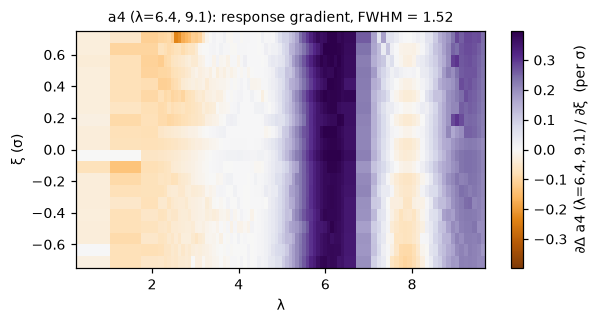

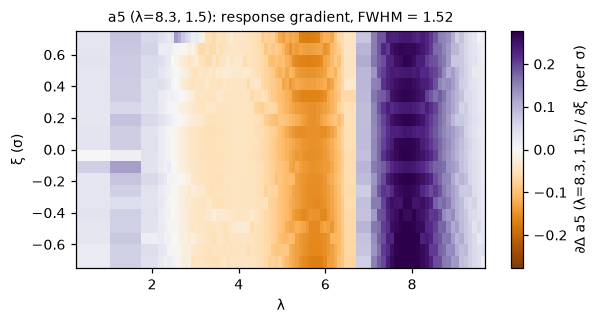

In [11]:
for p in EXAMPLES:
    plotting.gradient_map(result, output=p, names=ins.NAMES, xlabel="λ")

The **callouts** pick out the most interesting columns automatically. Here we only draw the column with the most
positive importance and the one with the most negative above the map (`n_nonlinear=0` turns off the columns that bend
furthest from a straight line, which would otherwise go below it). The dashed line is the straight-line response that
the importance alone would predict, so where the two part, the saturation and the prior bounds are starting to show.
With `threshold` set to the amplitude's retrieved σ, any response bigger than its error bar is blacked out, which
shows where perturbations of a few σ move the answer by more than its uncertainty.

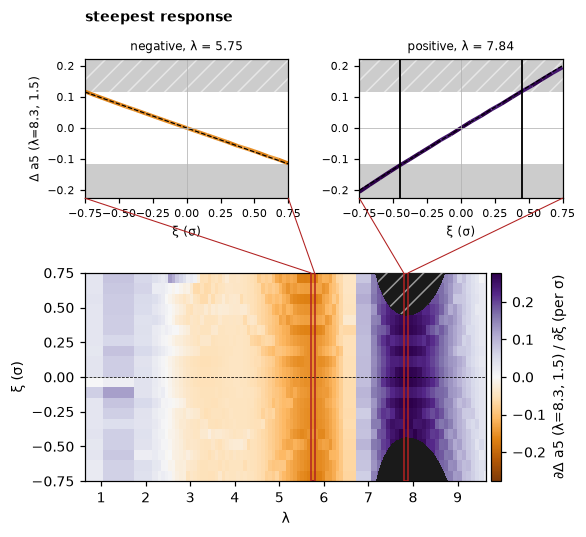

In [12]:
plotting.callouts(result, output=4, threshold=sig[4], names=ins.NAMES, xlabel="λ", n_positive=1, n_negative=1, n_nonlinear=0);

## Step 5: designing the instrument

### Scoring every point

The importance is in amplitude units per σ of the point. Dividing it by the parameter's retrieved σ tells us how far
the answer moves, in units of its own error bar, when that region of the observation moves by its noise. Once this is
also divided by the window's total weight over the points, it gives each point's **score** for each parameter. This
last step matters because a window in a spectrograph moves around 20 bins at once, whereas one over the filters only
moves 2 or 3, so without it a lone filter would look less important than a spectrograph bin simply for having fewer
neighbours.

The design rule removes one point per step:

1. Each parameter **protects its top `TOP_K` points**, so that nothing one parameter depends on is lost just because
   the others don't need it.
2. Of the unprotected points, the one with the **lowest total score** is removed:
   - a **filter** is dropped;
   - an **end bin** of a spectrograph is cropped;
   - an **interior bin** is merged with its lower-scoring neighbour, but only if that neighbour is unprotected. If
     both of its neighbours are protected, it stays, and the next-lowest point goes instead. Merging keeps the light,
     at a lower resolution but with lower noise.
3. Once there are no unprotected points left that can be removed, protection is ignored, so the loop runs all the way
   down to no points at all.

The score plot below is redrawn in place at every step of the loop, so you can watch the scores, the protected points
and the next removal change as the instrument shrinks.

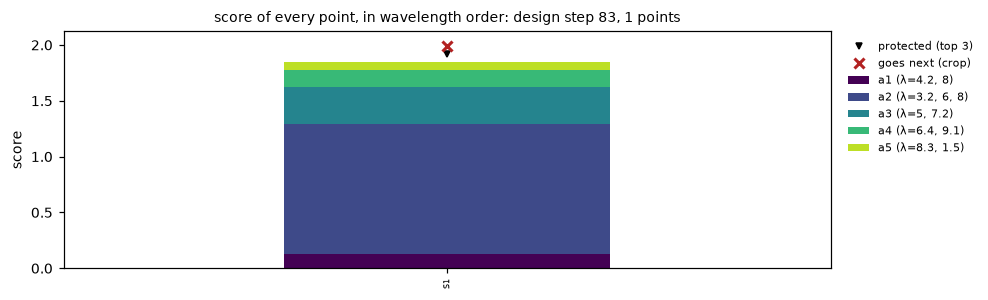

design steps: 100%|██████████| 84/84 [01:17<00:00,  1.08it/s]

84 steps to no points; design after 67 steps: 84 -> 17 points


In [13]:

MAX_LOSS = 0.5    # the design is the smallest instrument losing at most this fraction of precision on any parameter
TOP_K = 3

def draw_scores(ax, o, s, step=None):
    # draw the stacked score of every point of observation o, its protected points and the one that goes next. It
    # redraws from scratch, so the design loop can update the same figure at each step
    ax.clear()
    protected = np.unique(np.argsort(-s, axis=0)[:TOP_K])
    nxt, kind, partner = ins.next_point(o, s, k=TOP_K)
    bottom = np.zeros(len(s))
    for p, c in enumerate(plt.cm.viridis(np.linspace(0, 0.9, len(ins.NAMES)))):
        ax.bar(np.arange(len(s)), s[:, p], bottom=bottom, color=c, width=0.85, label=ins.NAMES[p])
        bottom += s[:, p]
    top = bottom.max()
    ax.plot(protected, bottom[protected] + 0.04 * top, "v", color="k", ms=4, label=f"protected (top {TOP_K})")
    ax.plot(nxt, bottom[nxt] + 0.08 * top, "x", color="firebrick", ms=7, mew=2, label=f"goes next ({kind})")
    if kind == "merge":
        ax.plot(partner, bottom[partner] + 0.08 * top, "o", color="firebrick", ms=4, mew=2, label=f"merges into ({kind})")
    ax.set_xticks(np.arange(len(s)), o["element"], rotation=90, fontsize=5)
    ax.set_xlim(-1, len(s)); ax.set_ylim(0, 1.15 * top); ax.set_ylabel("score")
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title("score of every point, in wavelength order"
                 + ("" if step is None else f": design step {step}, {len(s)} points"), fontsize=9)
    return nxt, kind, partner

s = ins.scores(result, sig)                               # (M, P)
fig_scores, ax_scores = plt.subplots(figsize=(9, 2.8))
nxt, kind, partner = draw_scores(ax_scores, obs, s)
score_display = display(fig_scores, display_id=True)   # the design loop below redraws this plot in place
plt.close(fig_scores)                                   # shown once, through the handle


config, history = full, []
for _ in tqdm(range(len(obs["y"])), desc="design steps"):   # one point fewer per step, down to none
    o = ins.observe(config, A_TRUE)
    fo = ins.retrieval(o)
    cv = ins.covariance(o, fo.best)
    sg = np.sqrt(np.diag(cv))
    history.append(dict(config=config, obs=o, best=fo.best, cov=cv, sigma=sg))
    r = pt.Perturber(fo, o["x_axis"], o["sigma"], FWHM, scale="own", batch_size=1)(o["y"], pt.magnitude_grid(XI_MAX, K))
    sc = ins.scores(r, sg)
    draw_scores(ax_scores, o, sc, step=len(history) - 1)   # update the score plot above in place
    score_display.update(fig_scores)
    config = ins.design_step(config, o, sc, k=TOP_K)

ratio = np.array([h["sigma"] / history[0]["sigma"] for h in history])
DESIGN = int(np.flatnonzero((ratio > 1 + MAX_LOSS).any(axis=1))[0]) - 1
design = history[DESIGN]
print(f"{len(history)} steps to no points; design after {DESIGN} steps: "
      f"{len(history[0]['obs']['y'])} -> {len(design['obs']['y'])} points")

**How the instrument shrinks** is shown on the left, with one row per step showing the filters it keeps (their
profiles) and the spectrograph bins (a tick at every bin edge, on a line over the spectrograph's range, so merged bins
have their ticks further apart). **The retrieval's precision** is shown on the right, as each amplitude's retrieved σ
against that of the full instrument, on the same rows. The dashed line is the `MAX_LOSS` threshold, and the horizontal
line marks the design, which is the last row inside it. Once the region a parameter depends on is gone, its σ climbs
up to the width of the prior.

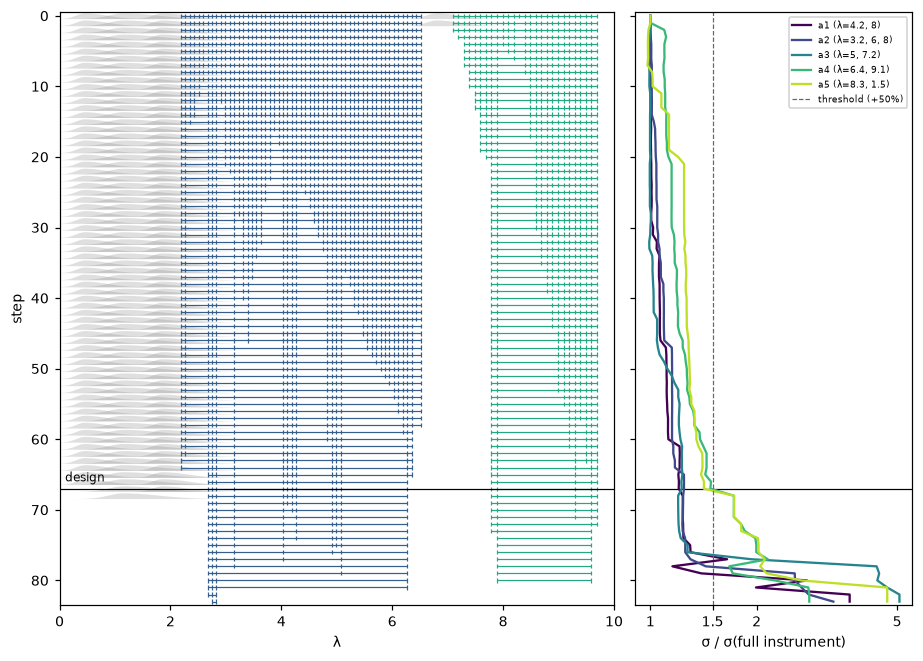

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 7), sharey=True, gridspec_kw=dict(width_ratios=[2, 1], wspace=0.05))
for i, h in enumerate(history):
    draw_filters(a1, h["config"]["filters"], base=i + 0.4, height=-0.8)
    for name in ins.SPECTROGRAPHS:
        e = h["config"][name]
        if e is not None:
            draw_bins(a1, name, e, i, 0.3)
for ax in (a1, a2):
    ax.axhline(DESIGN, color="k", lw=0.8)
a1.text(0.1, DESIGN - 0.6, "design", fontsize=8, va="bottom")
a1.set_xlim(0, 10); a1.set_ylim(len(history) - 0.5, -0.5)
a1.set_xlabel("λ"); a1.set_ylabel("step")

for p, c in zip(range(len(ins.NAMES)), plt.cm.viridis(np.linspace(0, 0.9, len(ins.NAMES)))):
    a2.plot(ratio[:, p], np.arange(len(history)), color=c, lw=1.5, label=ins.NAMES[p])
a2.axvline(1 + MAX_LOSS, color="0.4", ls="--", lw=0.8, label=f"threshold (+{MAX_LOSS:.0%})")
a2.set_xscale("log"); a2.set_xlabel("σ / σ(full instrument)")
a2.set_xticks([1, 1 + MAX_LOSS, 2, 5], ["1", f"{1 + MAX_LOSS:g}", "2", "5"]); a2.minorticks_off()
a2.legend(fontsize=6, loc="upper right", framealpha=0.9);

## The design next to the full instrument

On the left are the full instrument and the design, with their observations. On the right is the posterior from each
as a corner plot, against the truth (black lines), with the full instrument in grey and the design in red.

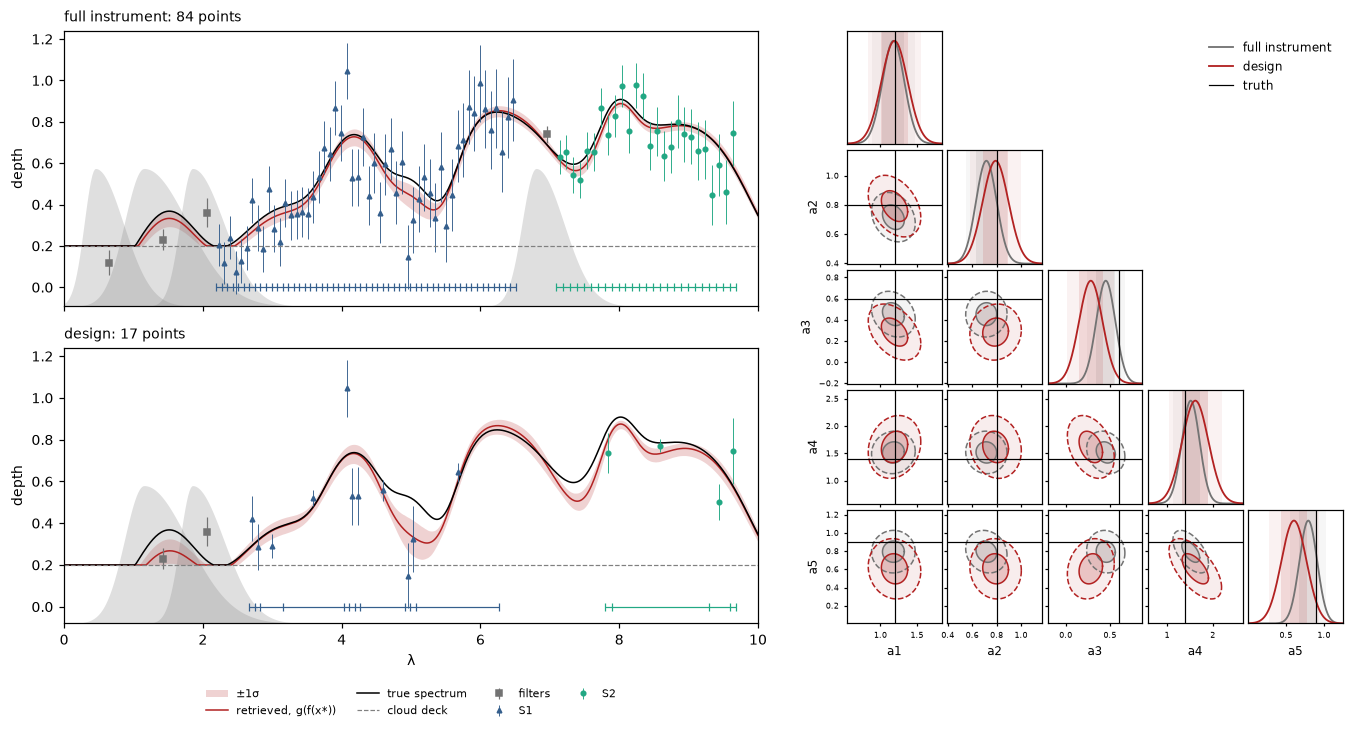

In [15]:
fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(1, 2, width_ratios=[1.4, 1], wspace=0.15)
left = gs[0].subgridspec(2, 1, hspace=0.15)
axes = [fig.add_subplot(left[0]), None]
axes[1] = fig.add_subplot(left[1], sharex=axes[0])
for ax, h, title in zip(axes, (history[0], design), ("full instrument", "design")):
    retrieved_spectrum(ax, h["obs"], h["best"])
    draw_instrument(ax, h["config"], h["obs"])
    ax.set_ylabel("depth"); ax.set_title(f"{title}: {len(h['obs']['y'])} points", fontsize=9, loc="left")
axes[1].legend(*axes[0].get_legend_handles_labels(), fontsize=7, frameon=False, loc="upper center",
               bbox_to_anchor=(0.5, -0.2), ncols=4)
axes[1].set_xlabel("λ")
axes[0].tick_params(labelbottom=False)

corner(fig, gs[1], [("full instrument", history[0]["best"], history[0]["cov"], "0.45"),
                    ("design", design["best"], design["cov"], "firebrick")]);

The design keeps every parameter within `MAX_LOSS` of the full instrument's precision, with fewer data points. Ok, this is an extreme case, and but it is a good demonstration of the method. In a real case, you would start with a more sensible instrument, and the design loop would be used to trim it down to
a smaller, cheaper one that still meets your science goals.

**Caveats.** The importance is of a *region* the width of the kernel, not of one point. A point's score includes its
neighbours, so the loop removes points in the order that their whole neighbourhood stops mattering. The design is also
tied to this one observation and noise realisation, so to use this for real planning you should repeat it over
plausible truths and noise draws.

## Using it on your own retrieval

```python
import perturb as pt
from perturb import plotting
fit = pt.fit_kernel_width(X_prior, x_axis)                                     # 1. kernel width
perturber = pt.Perturber(f, x_axis, sigma, fit["fwhm"], scale="own", batch_size=1)  # f: one fit per call
wide = perturber(x, pt.magnitude_grid(5, 41))                                       # explore
xi_max = pt.max_magnitude(pt.in_distribution_curve(wide, forward, tol=0.1))         # 2. how far
result = perturber(x, pt.magnitude_grid(xi_max, 21))                                # 3. perturb
plotting.gradient_map(result, output=0)                                             # 4. plot
score = np.abs(result.importance) / sigma_retrieved                                 # 5. what each point is worth
```